In [1]:
# env: tf
# population studies using multi-class classification
import numpy as np
import pandas as pd
from matplotlib import pyplot
from scipy.stats import binom
print(np.__version__)
from scipy.optimize import minimize

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve
from sklearn.calibration import calibration_curve

import os
import sys
if '../../lib/' not in sys.path:
    sys.path.append('../../lib/')
import dio3
import multi_fgl_utils as util
import plot_util as putil

1.24.3


In [2]:
if 1:
    import importlib
    importlib.reload(util);


In [3]:
def gauss_pdf(mu, sigma):
    pf = 1 / np.sqrt(2. * np.pi * sigma**2)
    def f(x):
        return pf * np.exp(-(x - mu)**2 / (2. * sigma**2))
    return f

In [4]:
# select the catalog and the case
cat_name = '4FGL-DR4' # '4FGL-DR3'
if cat_name == '4FGL-DR4':
    baseline_case = '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp'
    case = '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp' 
    #baseline_case = '4FGL-DR4_GMM_RF'
    #case = '4FGL-DR4_GMM_RF' # '4FGL-DR4_GMM_RF_no_prune'
    baseline_case = '4FGL-DR4_2class_RF' # '4FGL-DR4_GMM_RF', '4FGL-DR4_2class_RF'
    case = '4FGL-DR4_2class_RF'

elif cat_name == '4FGL-DR3':
    baseline_case = '4FGL-DR3_GMM_RF'
    case = '4FGL-DR3_GMM_RF' 
    
baseline = (case == baseline_case)
root_folder = '../../'
config_folder = root_folder + 'config/'

# generic inputs
cdict = util.get_config_dict(baseline_case=baseline_case, 
                             case=case, 
                             folder=config_folder)

cdict['root_folder'] = root_folder
folder_in = cdict['root_folder'] + cdict.get('folder_in', 'data_in/')
folder_out = cdict.get('folder_out', root_folder + 'data_out/')
folder = folder_out
Eind = int(cdict.get('Eind', 1000))
class_name = cdict.get('class_name', 'CLASS1')

cat_folder = '%s/results/%s_probabilistic_catalogs/' % (cdict['root_folder'], util.get_cat_descr(cdict))
cat_fn = cat_folder + util.get_cat_descr(cdict) + '_prob_cat.csv'
cat_df = pd.read_csv(cat_fn, index_col=0)

assoc_sources = cdict.get('assoc_sources', 'all_assoc')
sep_model = cdict.get('sep_model', 'GMM')
tree_alg = sep_model
#sep_model = 'RF' # 'GMM', 'RF'
nmin = cdict.get('nmin')
if nmin is not None: 
    nmin = int(nmin)
max_depth = int(cdict.get('max_depth', 5))
feature_mode = cdict.get('features', 'all_features')


tree_cat_fn = util.get_tree_cat_fn(cdict)
tree_cat_dict = dio3.loaddict(tree_cat_fn)
if util.exist_internal(tree_cat_dict):
    util.remove_internal(tree_cat_dict)
max_tree_cat_dict = util.tree2max_tree(tree_cat_dict)
dec_tree_cat_dict = util.max_tree2dec_tree(max_tree_cat_dict)
nodes = [str(key) for key in dec_tree_cat_dict.keys()]

        

all_assoc = []
for cls in tree_cat_dict.values():
    all_assoc.extend(cls)

xdf_fn = util.get_xdf_fn(cdict)
xdf = pd.read_csv(xdf_fn, index_col=0)
ns = len(xdf)

all_features = [name for name in xdf.columns if name.find('CLASS') == -1]
if feature_mode == 'all_features':
    features = all_features
elif feature_mode == 'no_coord_features':
    features = [feat for feat in all_features if feat.find('GL') == -1]


nsrc_dict = util.get_nsrc_dict(xdf, class_column=class_name, classes='associated')
nsrc_df = util.nsrc_dict2df(nsrc_dict)

if 0:
    # algorithm description string
    pars_dict = util.pars_dict
    pars_dict['NN']['nfeatures'] = len(features)
    pars_dict['NN']['epochs'] = cdict.get('epochs', 500)
    #alg_descr = util.get_alg_descr(cdict, pars_dict=pars_dict)

descr_str = util.get_cat_descr(cdict)



# some legacy parameters
add_4lac = False


FileNotFoundError: [Errno 2] No such file or directory: '../..//results/4FGL-DR4_2classes_2class_gal_egal_probabilistic_catalogs/4FGL-DR4_2classes_2class_gal_egal_prob_cat.csv'

In [5]:
descr_str

'4FGL-DR4_5classes_GMM_no_bcu_spp_no_coord_features'

In [6]:
features

['log10(Energy_Flux100)',
 'log10(Unc_Energy_Flux100)',
 'log10(Signif_Avg)',
 'LP_index1000MeV',
 'LP_beta',
 'LP_SigCurv',
 'log10(Variability_Index)']

In [7]:
algs = ['RF',]
#algs = ['RF','NN']

fig_size =  [8, 6]
fig_1d_dict = {'fig_size':fig_size, 'axes.titlesize': 22}

colors = pyplot.rcParams['axes.prop_cycle'].by_key()['color']
lss = {'RF':'--', 'NN':'-.'}
plot_all_assoc = False

save_plots = 1
save_png = 0
copy2tex = 0

plots_folder = '%s/plots/pop_study/%s/' % (cdict['root_folder'], descr_str)
plots_folder_extra = plots_folder + 'extra/'
paper_folder = '/Users/Dmitry/Work/Fermi/fermi_multiclass_papers/4_msp_sp_evolution/msp_sp_evolution_git/'
plots_folder_paper = paper_folder + 'plots/'
    
if not os.path.isdir(plots_folder):
    os.makedirs(plots_folder)

if not os.path.isdir(plots_folder_extra):
    os.makedirs(plots_folder_extra)

if not os.path.isdir(plots_folder_paper):
    os.makedirs(plots_folder_paper)


In [8]:
if 0:
    folder = '../../data_out/'
    tree_alg = 'RF' # 'stat', 'GMM', 'RF', '4class', tree_alg == '2class_gal_egal'
    mode = 'no_bcu_spp' # 'all_assoc', 'no_bcu_spp'
    if mode == 'all_assoc':
        mode_str = ''
    else:
        mode_str = '_%s' % mode

    class_name = 'CLASS1'
    descr_str = ''
    if tree_alg == 'GMM':
        nmin = 100
        tree_cat_fn = folder + 'tree_cat_nmin%i%s.yaml' % (nmin, mode_str)
        descr_str += '_nmin%i_%s%s' % (nmin, tree_alg, mode_str)
    elif tree_alg == 'RF':
        if mode == 'no_bcu_spp':
            nmin = 60
        else:
            nmin = 100
        tree_cat_fn = folder + 'tree_cat_nmin%i_RF%s.yaml' % (nmin, mode_str)
        descr_str += '_nmin%i_%s%s' % (nmin, tree_alg, mode_str)

    elif tree_alg == '2class_gal_egal':
        tree_cat_fn = folder + 'tree_cat_2class_gal_egal.yaml'
        title_dict = {'00': 'Extragalactic', '01': 'Galactic'}
        plots_folder = '../../plots/dfg/pop_studies/'


    tree_cat_dict = dio3.loaddict(tree_cat_fn)
    nclasses = len(tree_cat_dict)
    max_tree_cat_dict = util.tree2max_tree(tree_cat_dict)
    dec_tree_cat_dict = util.max_tree2dec_tree(max_tree_cat_dict)
    nodes = [str(key) for key in dec_tree_cat_dict.keys()]

    folder_in = '../../results/4FGL-DR3_probabilistic_classification/'
    alg_descr = '_%s' % tree_alg
    if tree_alg == 'GMM' or tree_alg == 'RF':
        alg_descr += '_nmin%s' % (nmin)
    elif tree_alg == '2class':
        alg_descr += '_gal_egal'
    alg_descr += mode_str
    feature_mode = 'no coord features'
    if feature_mode == 'no coord features':
        alg_descr += '_no_coord_features'


    if tree_alg == 'GMM' or tree_alg == 'RF':
        fn = folder_in + '4FGL-DR3_%iclass%s_prob_cat.csv' % (nclasses, alg_descr)
        #fn = folder_in + '4FGL-DR3_%iclass_pcat.csv' % nclasses
        #algs = ['RF', 'NN']
        algs = ['RF',]
    elif tree_alg == '2class_gal_egal':
        fn = folder_in + '4FGL-DR3_%s_pcat.csv' % tree_alg
        #algs = ['RF', 'NN']
        algs = ['RF',]

    print(fn)
    cat_df = pd.read_csv(fn, index_col=0)
    all_assoc = []
    for cls in tree_cat_dict.values():
        all_assoc.extend(cls)

    fig_size =  [8, 6]
    fig_1d_dict = {'fig_size':fig_size, 'axes.titlesize': 22}


In [9]:
print(util.cl_list2str(all_assoc))

nlsy1, css, fsrq, ssrq, rdg, sbg, sey, bll, agn, hmb, psr, lmb, nov, bin, snr, gc, sfr, pwn, glc, gal, msp


In [10]:
print(util.cl_list2str(features))

log10(Energy_Flux100), log10(Unc_Energy_Flux100), log10(Signif_Avg), LP_index1000MeV, LP_beta, LP_SigCurv, log10(Variability_Index)


In [11]:
if add_4lac:
    from astropy.io import fits
    fn = '../data_in/table-4LAC-DR2-h.fits'
    hdu = fits.open(fn)
    lach = hdu[1].data
    fn = '../data_in/table-4LAC-DR2-l.fits'
    hdu = fits.open(fn)
    lacl = hdu[1].data
    #cnames = [cat_hdu[1].header[key] for key in cat_hdu[1].header.keys() if key.startswith('TTYPE')]
    #cnames = [clm.name for clm in lach.columns]
    lac_lats = list(lach['GLAT']) + list(lacl['GLAT'])
    sin_lac_lats = np.sin(np.deg2rad(lac_lats))
    print(len(lach), len(lacl))

In [12]:
if 0:
    # already defined
    folder = '../../data_out/'
    Eind = 1000
    xdf_fn = folder + 'xdf_fgl_Eind%iMeV.csv' % Eind
    #xdf_fn = folder + 'xdf_fgl.csv'
    xdf = pd.read_csv(xdf_fn, index_col=0)
    features = [name for name in xdf.columns if name != 'CLASS1']
    ns = len(xdf)

    #unas_mask = (cat_df['CLASS1'] == 'unas') | (cat_df['CLASS1'] == 'unk')



In [13]:
assoc_mask = util.get_cl_mask(all_assoc, xdf, cname=class_name)
unas_type = 'all_not_assoc' # 'unas', 'unk', bcu', 'spp', 'all_not_assoc'
descr_str += '_%s' % unas_type
if unas_type == 'all_not_assoc':
    unas_mask = ~assoc_mask
    unas_label = 'unas unk bcu spp'
else:
    unas_mask = util.get_cl_mask([unas_type], xdf, cname=class_name)
    unas_label = unas_type


In [14]:
if tree_alg == 'GMM' or tree_alg == 'RF':
    pgroup1 = nodes[:3]
    pgroup2 = nodes[3:]
elif tree_alg == '2class_gal_egal':
    pgroup1 = nodes[:1]
    pgroup2 = nodes[1:]

In [15]:
putil.setup_figure_pars()
size = 3
ncols = 1
nrows1 = len(pgroup1)
nrows2 = len(pgroup2)
fig_size_1plot = pyplot.rcParams['figure.figsize']
if nrows1 == 1 and nrows2 == 1:
    fig_size1 =  pyplot.rcParams['figure.figsize']
    fig_size2 =  pyplot.rcParams['figure.figsize']
else:
    pyplot.rcParams['axes.titlesize'] =  16
    pyplot.rcParams['figure.subplot.bottom'] =  0.08
    pyplot.rcParams['figure.subplot.top'] =  0.97
    pyplot.rcParams['figure.subplot.left'] =  0.20
    pyplot.rcParams['figure.subplot.right'] =  0.93

    fig_width = size * ncols + size/2  # width in inches
    
    fig_height1 = size * nrows1 + size/2   # height in inches
    
    fig_height2 = size * nrows2 + size/2   # height in inches
    fig_size1 =  [fig_width, fig_height1]
    fig_size2 =  [fig_width, fig_height2]




In [16]:
cls_masks = {}
for node in nodes:
    cls_masks[node] = util.get_cl_mask(dec_tree_cat_dict[int(node)], xdf, cname='CLASS1')

In [17]:
# feature mask
fmask0 = np.ones(len(xdf), dtype=bool)
bmask = 10
fmask_hlat = np.abs(xdf['sin(GLAT)']) > np.sin(np.deg2rad(bmask)) # select high latitudes
fmask_llat = np.abs(xdf['sin(GLAT)']) < np.sin(np.deg2rad(bmask)) # select low latitudes
lmask = 10
fmask_lon_out = xdf['cos(GLON)'] < np.cos(np.deg2rad(lmask)) # select outer galaxy
fmask_lon_in = xdf['cos(GLON)'] > np.cos(np.deg2rad(lmask)) # select inner galaxy

In [18]:
# lat plot
plot_sin_glat = True
sin_glat = xdf['sin(GLAT)']
sin_glat_bins = np.linspace(-1, 1, 13)
if plot_sin_glat:
    binc = (sin_glat_bins[1:] + sin_glat_bins[:-1]) / 2.
    xlabel = 'sin(GLAT)'
else:
    glat_bins = np.rad2deg(np.arcsin(sin_glat_bins))
    binc = (glat_bins[1:] + glat_bins[:-1]) / 2.
    xlabel = 'GLAT'
bins = sin_glat_bins
values = sin_glat


In [19]:
#fmask = fmask_lon_out
#fmask = fmask_lon_in
#fmask = fmask_llat
fmask = True
hist_all_assoc = np.histogram(values[assoc_mask & fmask], bins=bins)[0]
hist_all_unassoc = np.histogram(values[unas_mask & fmask], bins=bins)[0]


if add_4lac:
    lac_sin_lats_hist = np.histogram(sin_lac_lats, bins=bins)[0]
    
assoc_count_hists = {}
assoc_prob_hists = {}
unas_hists = {}
for node in nodes:
    assoc_count_hists[node] = np.histogram(values[cls_masks[node] & fmask], bins=bins)[0]
    for alg in algs:
        key = '%s_%s' % (node, alg)
        assoc_prob_hists[key] = np.histogram(values[assoc_mask & fmask], bins=bins, 
                                      weights=cat_df[key][assoc_mask & fmask])[0]
        unas_hists[key] = np.histogram(values[unas_mask & fmask], bins=bins, 
                                      weights=cat_df[key][unas_mask & fmask])[0]



In [20]:
fig_size1, fig_size2

([4.5, 10.5], [4.5, 7.5])

In [21]:
purpose = None #'DFG'

save figure to file: ../..//plots/pop_study/4FGL-DR4_5classes_GMM_no_bcu_spp_no_coord_features/lat_profile_group1_4FGL-DR4_5classes_GMM_no_bcu_spp_no_coord_features_all_not_assoc.pdf


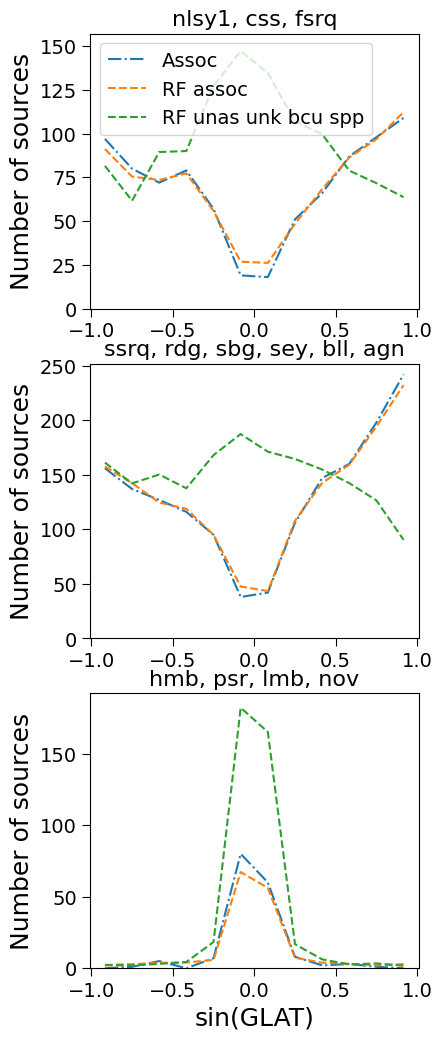

In [22]:
ymin = 0
pgroup = pgroup1
nrows = len(pgroup)
pyplot.rcParams['figure.figsize'] =  fig_size1

pyplot.figure()
for ind, node in enumerate(pgroup):
    ax = pyplot.subplot(nrows, ncols, ind + 1)
    ymax = 0
    if plot_all_assoc:
        pyplot.plot(binc, hist_all_assoc, ls=':', c=colors[0], label='Assoc')
        pyplot.plot(binc, hist_all_unassoc, ls=':', c=colors[1], label=unas_label)
        ci = 2
    else:
        ci = 0
        
    
    pyplot.plot(binc, assoc_count_hists[node], ls='-.', c=colors[ci], 
                     label='Assoc')

    ymax = np.maximum(ymax, np.max(assoc_count_hists[node]) + 10)
    ci += 1
    
    for alg in algs:
        key = '%s_%s' % (node, alg)
        if purpose == 'DFG':
            ls = ':'
        else:
            ls = lss[alg]
        pyplot.plot(binc, assoc_prob_hists[key], ls=ls, c=colors[ci], 
                         label=alg + ' assoc')
        ymax = np.maximum(ymax, np.max(assoc_prob_hists[key]) + 10)
            
    ci += 1
    for alg in algs:
        key = '%s_%s' % (node, alg)
        if purpose == 'DFG':
            ls = '--'
        else:
            ls = lss[alg]

        
        pyplot.plot(binc, unas_hists[key], ls=ls, c=colors[ci], 
                         label='%s %s' % (alg, unas_label))
        ymax = np.maximum(ymax, np.max(unas_hists[key]) + 10)
    

    if all(fmask == fmask_lon_in):
        text = r'$|\ell| < %i^\circ$' % lmask
    elif all(fmask == fmask_lon_out):
        text = r'$|\ell| > %i^\circ$' % lmask
    else:
        text = ''
    ax.text(0.8, 0.9, text, fontsize=16, horizontalalignment='left', 
                    verticalalignment='bottom', transform=ax.transAxes)

    if purpose == 'DFG':
        for alg in algs:
            ci += 1
            key = '%s_%s' % (node, alg)
            ys = assoc_count_hists[node] + unas_hists[key]
            pyplot.plot(binc, ys, ls='-', c=colors[ci],
                             label='Assoc + %s unas' % alg)
            ymax = np.maximum(ymax, np.max(ys) + 30)
    
            pyplot.plot(binc, np.mean(ys) * np.ones_like(binc), ls='--', c=colors[ci],
                             label='Mean')
    if add_4lac:
        ci += 1
        pyplot.plot(binc, lac_sin_lats_hist, ls=':', c=colors[ci],
                             label='4LAC-DR2')
        

    pyplot.ylim(ymin, ymax)
    if ind == 0:
        if purpose == 'DFG':
            pyplot.legend(loc=(0.64, 0.25), fontsize=14, labelspacing=0.2)
        else:
            pyplot.legend(loc='upper left')

    if ind == len(pgroup) - 1:
        pyplot.xlabel(xlabel)
    pyplot.ylabel('Number of sources')
    cls_str = util.cl_list2str(dec_tree_cat_dict[int(node)])
    if purpose == 'DFG' and tree_alg == '2class_gal_egal':
        pyplot.title('Extragalactic')
    else:
        pyplot.title(cls_str)
if save_plots and purpose != 'DFG':
    fn = plots_folder + 'lat_profile_group1_%s.pdf' % descr_str
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn)
    if save_png:
        fn_png = fn.replace('.pdf', '.png')
        pyplot.savefig(fn_png)
    if copy2tex:
        fn_paper = fn.replace(plots_folder, plots_folder_paper)
        cmd = 'cp %s %s' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)



save figure to file: ../..//plots/pop_study/4FGL-DR4_5classes_GMM_no_bcu_spp_no_coord_features/lat_profile_group2_4FGL-DR4_5classes_GMM_no_bcu_spp_no_coord_features_all_not_assoc.pdf


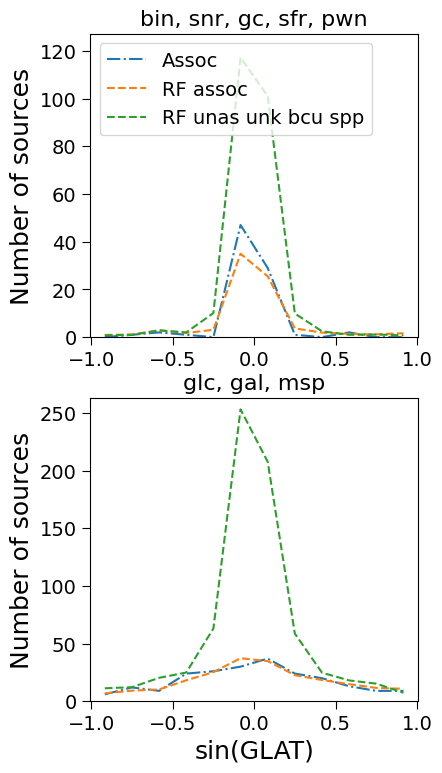

In [23]:
ymin = 0
pgroup = pgroup2
nrows = len(pgroup)
pyplot.rcParams['figure.figsize'] =  fig_size2


pyplot.figure()
for ind, node in enumerate(pgroup):
    ax = pyplot.subplot(nrows, ncols, ind + 1)
    if node not in assoc_count_hists:
        continue
    ymax = 0
    if plot_all_assoc:
        pyplot.plot(binc, hist_all_assoc, ls=':', c=colors[0], label='Assoc')
        pyplot.plot(binc, hist_all_unassoc, ls=':', c=colors[1], label=unas_label)
        ci = 2
    else:
        ci = 0
        
    
    pyplot.plot(binc, assoc_count_hists[node], ls='-.', c=colors[ci], 
                     label='Assoc')

    ymax = np.maximum(ymax, np.max(assoc_count_hists[node]) + 10)
    ci += 1
    
    for alg in algs:
        key = '%s_%s' % (node, alg)
        if purpose == 'DFG':
            ls = ':'
        else:
            ls = lss[alg]
        pyplot.plot(binc, assoc_prob_hists[key], ls=ls, c=colors[ci], 
                         label=alg + ' assoc')
        ymax = np.maximum(ymax, np.max(assoc_prob_hists[key]) + 10)
            
    for alg in algs:
        ci += 1
        key = '%s_%s' % (node, alg)
        if purpose == 'DFG':
            ls = '--'
        else:
            ls = lss[alg]

        pyplot.plot(binc, unas_hists[key], ls=ls, c=colors[ci], 
                         label='%s %s' % (alg, unas_label))
        ymax = np.maximum(ymax, np.max(unas_hists[key]) + 10)
    

    
    if purpose == 'DFG':
        for alg in algs:
            ci += 1
            key = '%s_%s' % (node, alg)
            ys = assoc_count_hists[node] + unas_hists[key]
            pyplot.plot(binc, ys, ls='-', c=colors[ci], 
                             label='Assoc + %s %s' % (alg, unas_label))
            ymax = np.maximum(ymax, np.max(ys) + 30)
    
    if all(fmask == fmask_lon_in):
        text = r'$|\ell| < %i^\circ$' % lmask
    elif all(fmask == fmask_lon_out):
        text = r'$|\ell| > %i^\circ$' % lmask
    else:
        text = ''
    ax.text(0.8, 0.9, text, fontsize=16, horizontalalignment='left', 
                    verticalalignment='bottom', transform=ax.transAxes)

    
    pyplot.ylim(ymin, ymax)
    if ind == 0:
        if purpose == 'DFG':
            pyplot.legend(loc='upper right', fontsize=14, labelspacing=0.2)
        else:
            pyplot.legend(loc='upper left')
    if ind == len(pgroup) - 1:
        pyplot.xlabel(xlabel)
    pyplot.ylabel('Number of sources')
    cls_str = util.cl_list2str(dec_tree_cat_dict[int(node)])
    if purpose == 'DFG' and tree_alg == '2class_gal_egal':
        pyplot.title('Galactic')
    else:
        pyplot.title(cls_str)
if save_plots and purpose != 'DFG':
    fn = plots_folder + 'lat_profile_group2_%s.pdf' % descr_str
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn)
    if save_png:
        fn_png = fn.replace('.pdf', '.png')
        pyplot.savefig(fn_png)
    if copy2tex:
        fn_paper = fn.replace(plots_folder, plots_folder_paper)
        cmd = 'cp %s %s' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)



In [24]:
# lon plot
values = np.rad2deg(np.arccos(xdf['cos(GLON)']))
values *= np.sign(xdf['sin(GLON)'])
bins = np.linspace(-180, 180, 37)
#bins = np.linspace(-180, 180, 19)
binc = (bins[1:] + bins[:-1]) / 2.
xlabel = 'GLON'


In [25]:
bins

array([-180., -170., -160., -150., -140., -130., -120., -110., -100.,
        -90.,  -80.,  -70.,  -60.,  -50.,  -40.,  -30.,  -20.,  -10.,
          0.,   10.,   20.,   30.,   40.,   50.,   60.,   70.,   80.,
         90.,  100.,  110.,  120.,  130.,  140.,  150.,  160.,  170.,
        180.])

In [26]:
fmask = fmask_llat
hist_all_assoc = np.histogram(values[assoc_mask & fmask], bins=bins)[0]
hist_all_unassoc = np.histogram(values[unas_mask & fmask], bins=bins)[0]

assoc_count_hists = {}
assoc_prob_hists = {}
unas_hists = {}
for node in nodes:
    assoc_count_hists[node] = np.histogram(values[cls_masks[node] & fmask], bins=bins)[0]
    for alg in algs:
        key = '%s_%s' % (node, alg)
        assoc_prob_hists[key] = np.histogram(values[assoc_mask & fmask], bins=bins, 
                                      weights=cat_df[key][assoc_mask & fmask])[0]
        unas_hists[key] = np.histogram(values[unas_mask & fmask], bins=bins, 
                                      weights=cat_df[key][unas_mask & fmask])[0]



save figure to file: ../..//plots/pop_study/4FGL-DR4_5classes_GMM_no_bcu_spp_no_coord_features/lon_profile_group1_4FGL-DR4_5classes_GMM_no_bcu_spp_no_coord_features_all_not_assoc.pdf


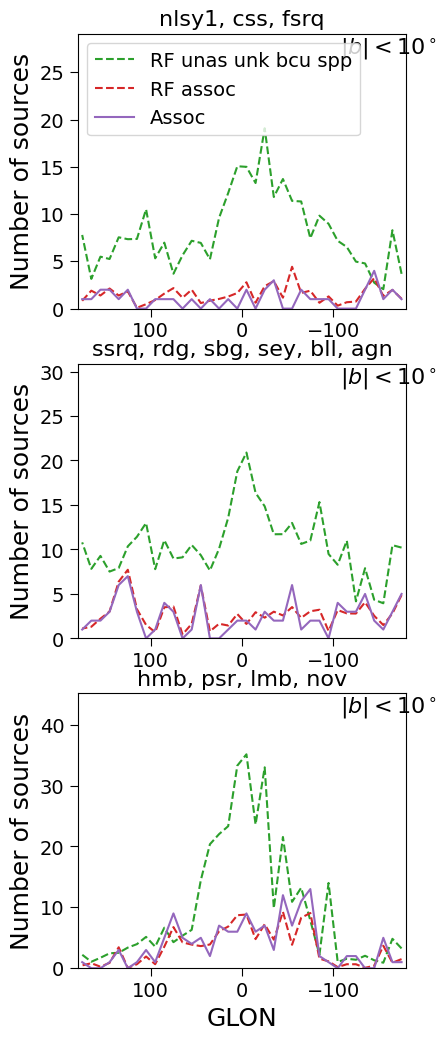

In [27]:
ymin = 0
pgroup = pgroup1
nrows = len(pgroup)
pyplot.rcParams['figure.figsize'] =  fig_size1


pyplot.figure()
for ind, node in enumerate(pgroup):
    ax = pyplot.subplot(nrows, ncols, ind + 1)
    ymax = 0
    if plot_all_assoc:
        pyplot.plot(binc, hist_all_assoc, ls=':', c=colors[0], label='Assoc')
        pyplot.plot(binc, hist_all_unassoc, ls=':', c=colors[1], label=unas_label)
    ci = 2
    
    for alg in algs:
        key = '%s_%s' % (node, alg)
        pyplot.plot(binc, unas_hists[key], ls=lss[alg], c=colors[ci], 
                         label='%s %s' % (alg, unas_label))
        ymax = np.maximum(ymax, np.max(unas_hists[key]) + 10)
    ci += 1
    
    for alg in algs:
        key = '%s_%s' % (node, alg)
        pyplot.plot(binc, assoc_prob_hists[key], ls=lss[alg], c=colors[ci], 
                         label=alg + ' assoc')
        ymax = np.maximum(ymax, np.max(assoc_prob_hists[key]) + 10)
    ci += 1
    pyplot.plot(binc, assoc_count_hists[node], ls='-', c=colors[ci], 
                     label='Assoc')
    
    if purpose == 'DFG':
        for alg in algs:
            ci += 1
            key = '%s_%s' % (node, alg)
            ys = assoc_count_hists[node] + unas_hists[key]
            pyplot.plot(binc, ys, ls='-', c=colors[ci],
                             label='Assoc + %s %s' % (alg, unas_label))
            ymax = np.maximum(ymax, np.max(ys) + 30)
    
            pyplot.plot(binc, np.mean(ys) * np.ones_like(binc), ls='--', c=colors[ci],
                             label='Mean')
        
    if all(fmask == fmask_llat):
        text = r'$|b| < %i^\circ$' % bmask
    elif all(fmask == fmask_hlat):
        text = r'$|b| > %i^\circ$' % bmask
    else:
        text = ''
    ax.text(0.8, 0.9, text, fontsize=16, horizontalalignment='left', 
                    verticalalignment='bottom', transform=ax.transAxes)

    ymax = np.maximum(ymax, np.max(assoc_count_hists[node]) + 10)
    pyplot.ylim(ymin, ymax)
    pyplot.xlim(180, -180)
    if ind == 0:
        pyplot.legend(loc='upper left')
    if ind == len(pgroup) - 1:
        pyplot.xlabel(xlabel)
    pyplot.ylabel('Number of sources')
    cls_str = util.cl_list2str(dec_tree_cat_dict[int(node)])
    pyplot.title(cls_str)
if save_plots and purpose != 'DFG':
    fn = plots_folder + 'lon_profile_group1_%s.pdf' % descr_str
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn)
    if save_png:
        fn_png = fn.replace('.pdf', '.png')
        pyplot.savefig(fn_png)
    if copy2tex:
        fn_paper = fn.replace(plots_folder, plots_folder_paper)
        cmd = 'cp %s %s' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)



save figure to file: ../..//plots/pop_study/4FGL-DR4_5classes_GMM_no_bcu_spp_no_coord_features/lon_profile_group2_4FGL-DR4_5classes_GMM_no_bcu_spp_no_coord_features_all_not_assoc.pdf


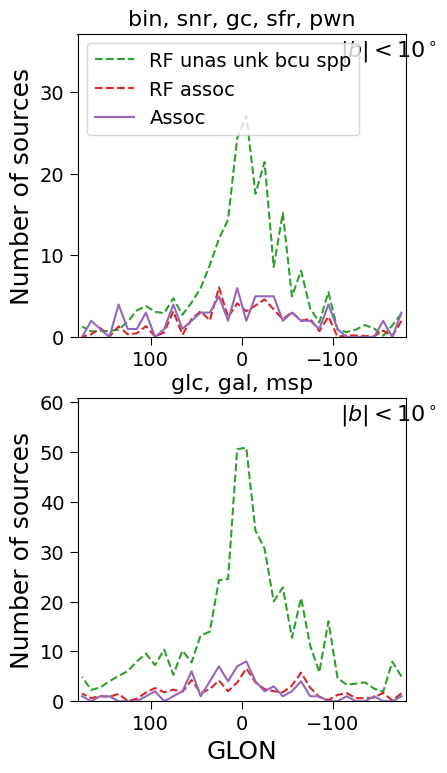

In [28]:
ymin = 0
pgroup = pgroup2
if purpose == 'DFG' and tree_alg == 'GMM':
    pyplot.rcParams['figure.figsize'] =  fig_size_1plot
else:
    pyplot.rcParams['figure.figsize'] =  fig_size2
    nrows = len(pgroup)


plot_all_unass = False
if not (purpose == 'DFG' and tree_alg == 'GMM'):
    pyplot.figure()
for ind, node in enumerate(pgroup):
    if purpose == 'DFG' and tree_alg == 'GMM':
        pyplot.figure()
        ax = pyplot.subplot(1, 1, 1)
    else:
        ax = pyplot.subplot(nrows, ncols, ind + 1)
    if node not in assoc_count_hists:
        continue

    ymax = 0
    if plot_all_assoc:
        pyplot.plot(binc, hist_all_assoc, ls=':', c=colors[0], label='Assoc')
    if plot_all_unass:
        pyplot.plot(binc, hist_all_unassoc, ls=':', c=colors[1], label=unas_label)
        ymax = np.maximum(ymax, np.max(hist_all_unassoc) + 10)
    ci = 2
    
    for alg in algs:
        key = '%s_%s' % (node, alg)
        if purpose == 'DFG':
            ls = '--' 
        else:
            ls = lss[alg]
        pyplot.plot(binc, unas_hists[key], ls=ls, c=colors[ci], 
                         label='%s %s' % (alg, unas_label))
        ymax = np.maximum(ymax, np.max(unas_hists[key]) + 10)
    ci += 1
    
    for alg in algs:
        key = '%s_%s' % (node, alg)
        if purpose == 'DFG':
            ls = '-.' 
        else:
            ls = lss[alg]
        pyplot.plot(binc, assoc_prob_hists[key], ls=ls, c=colors[ci], 
                         label=alg + ' assoc')
        ymax = np.maximum(ymax, np.max(assoc_prob_hists[key]) + 10)
    ci += 1
    pyplot.plot(binc, assoc_count_hists[node], ls='-', c=colors[ci], 
                     label='Assoc')
    
    if all(fmask == fmask_llat):
        text = r'$|b| < %i^\circ$' % bmask
    elif all(fmask == fmask_hlat):
        text = r'$|b| > %i^\circ$' % bmask
    else:
        text = ''
    ax.text(0.8, 0.9, text, fontsize=16, horizontalalignment='left', 
                    verticalalignment='bottom', transform=ax.transAxes)
    
    ymax = np.maximum(ymax, np.max(assoc_count_hists[node]) + 10)
    pyplot.ylim(ymin, ymax)
    pyplot.xlim(180, -180)
    if ind == 0 or purpose == 'DFG':
        pyplot.legend(loc='upper left')
    if ind == len(pgroup) - 1 or (purpose == 'DFG' and tree_alg == 'GMM'):
        pyplot.xlabel(xlabel)
    pyplot.ylabel('Number of sources')
    cls_str = util.cl_list2str(dec_tree_cat_dict[int(node)])
    
    
    if purpose == 'DFG':
        pyplot.yscale('log')
        pyplot.ylim(0.5, 3*ymax)
    if purpose == 'DFG' and tree_alg == '2class_gal_egal':
        pyplot.title('Galactic')
    else:
        pyplot.title(cls_str)
    if purpose == 'DFG' and tree_alg == 'GMM' and save_plots:
        fn = plots_folder + 'lon_profile_group2_%i_%s.pdf' % (ind, descr_str)
        print('save figure to file: %s' % (fn))
        pyplot.savefig(fn)

if save_plots and not (purpose == 'DFG' and tree_alg == 'GMM'):
    fn = plots_folder + 'lon_profile_group2_%s.pdf' % descr_str
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn)
    if save_png:
        fn_png = fn.replace('.pdf', '.png')
        pyplot.savefig(fn_png)
    if copy2tex:
        fn_paper = fn.replace(plots_folder, plots_folder_paper)
        cmd = 'cp %s %s' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)



In [29]:
xdf.columns

Index(['sin(GLAT)', 'cos(GLON)', 'sin(GLON)', 'log10(Energy_Flux100)',
       'log10(Unc_Energy_Flux100)', 'log10(Signif_Avg)', 'LP_index1000MeV',
       'LP_beta', 'LP_SigCurv', 'log10(Variability_Index)', 'CLASS1'],
      dtype='object')

In [30]:
#pyplot.hist(xdf['LP_SigCurv'], bins=range(30))

In [31]:
# a variable plot
mask_outliers = False
if 0:
    var_name = 'log10(Energy_Flux100)'
    xlabel = r'log10(Energy_Flux100 [$\rm erg\ cm^{−2} s^{−1}$])'
    xmin, xmax = -12.5, -9.
elif 0:
    var_name = 'LP_index1000MeV'
    xlabel = 'Index at 1 GeV'
    xmin, xmax = 1, 4.
    mask_outliers = True
elif 0:
    var_name = 'LP_beta'
    xlabel = 'LP beta'
    xmin, xmax = -0.2, 1.
    mask_outliers = True
elif 0:
    var_name = 'PL_Index'
    xlabel = 'PL index'
    xmin, xmax = 1, 4.
    mask_outliers = True
elif 0:
    var_name = 'log10E_cut'
    xlabel = 'log10(E cut)'
    xmin, xmax = 0., 8.
elif 0:
    var_name = 'Pivot_Energy'
    xlabel = 'Pivot_Energy'
    xmin, xmax = 0., 8.
elif 0:
    var_name = 'LP_SigCurv'
    xlabel = var_name
    xmin, xmax = 0., 20.
elif 1:
    var_name = 'log10Epeak'
    xlabel = var_name
    inds = xdf['LP_index1000MeV']
    beta = xdf['LP_beta']
    log10Epeak = 0.5 * (2. - inds) / beta
    log10Epeak = np.maximum(-1.1, log10Epeak)
    log10Epeak = np.minimum(2.1, log10Epeak)
    xdf[var_name] = log10Epeak
    xmin, xmax = -1., 2.
    
ncbins = 20
bins = np.linspace(xmin, xmax, ncbins + 1)
binc = (bins[1:] + bins[:-1]) / 2.
dx = bins[1] - bins[0]

bins_gauss = np.linspace(xmin, xmax, ncbins*10 + 1)
binc_gauss = (bins_gauss[1:] + bins_gauss[:-1]) / 2.

#xmin = bins[0]
#xmax = bins[-1]
density = False

In [32]:
if var_name in xdf.columns:
    print('take values from xdf')
    values = xdf[var_name]
else:
    # get values from 4FGL-DR3
    from astropy.io import fits
    fn = util.get_cat_fn(cdict)
    cat_hdu = fits.open(fn)
    ctab = cat_hdu[1].data 
    cols = [var_name]

    names = np.array([str(x).strip() for x in ctab['Source_Name']], dtype=str)
    df_extra = pd.DataFrame(index=names, columns=cols, data=0.)
    for col in cols:
        if col == 'log10E_cut':
            E0 = ctab['Pivot_Energy']
            d = ctab['PLEC_ExpfactorS']
            b = ctab['PLEC_Exp_Index']
            log10E = np.array(np.log10(E0) + np.log10(b**2 / d) / b)
            df_extra[col] = log10E
        elif col == 'Pivot_Energy':
            E0 = ctab['Pivot_Energy']
            df_extra[col] = np.array(E0) / 1000.
        else:
            df_extra[col] = np.array(ctab[col], dtype=float)
    values = df_extra[var_name][xdf.index]

take values from xdf


In [33]:
#ctab.dtype.names
np.min(values), np.max(values), bins

(-1.1,
 2.1,
 array([-1.  , -0.85, -0.7 , -0.55, -0.4 , -0.25, -0.1 ,  0.05,  0.2 ,
         0.35,  0.5 ,  0.65,  0.8 ,  0.95,  1.1 ,  1.25,  1.4 ,  1.55,
         1.7 ,  1.85,  2.  ]))

In [34]:
fmask = fmask_llat #fmask_llat & fmask_lon_in # fmask_hlat #
hist_all_assoc = np.histogram(values[assoc_mask & fmask], bins=bins, density=density)[0]
hist_all_unassoc = np.histogram(values[unas_mask & fmask], bins=bins, density=density)[0]

mean_dict = {'assoc':{}, 'unas':{}}
std_dict = {'assoc':{}, 'unas':{}}


assoc_count_hists = {}
assoc_prob_hists = {}
unas_hists = {}
for node in nodes:
    assoc_count_hists[node] = np.histogram(values[cls_masks[node] & fmask], bins=bins, density=density)[0]
    if mask_outliers:
        vmask = (values > xmin) & (values < xmax) # outlier mask?
    else:
        vmask = True
    mean_dict['assoc'][node] = np.mean(values[cls_masks[node] & fmask & vmask])
    std_dict['assoc'][node] = np.std(values[cls_masks[node] & fmask & vmask]) / np.sqrt(sum(fmask & vmask))
    for alg in algs:
        key = '%s_%s' % (node, alg)
        assoc_prob_hists[key] = np.histogram(values[assoc_mask & fmask], bins=bins, 
                                      weights=cat_df[key][assoc_mask & fmask], density=density)[0]
        unas_hists[key] = np.histogram(values[unas_mask & fmask], bins=bins, 
                                      weights=cat_df[key][unas_mask & fmask], density=density)[0]
        weights = cat_df[key][unas_mask & fmask & vmask]
        mean_dict['unas'][key] = np.sum(values[unas_mask & fmask & vmask] * weights) / np.sum(weights)
        var = np.sum((values[unas_mask & fmask & vmask] - mean_dict['unas'][key])**2 * weights**2) 
        var /= np.sum(weights)**2
        std_dict['unas'][key] = np.sqrt(var)
        


In [35]:
dec_tree_cat_dict, mean_dict, std_dict

({1: ['nlsy1', 'css', 'fsrq'],
  2: ['ssrq', 'rdg', 'sbg', 'sey', 'bll', 'agn'],
  3: ['hmb', 'psr', 'lmb', 'nov'],
  4: ['bin', 'snr', 'gc', 'sfr', 'pwn'],
  5: ['glc', 'gal', 'msp']},
 {'assoc': {'1': -0.984727326448496,
   '2': 0.9071697255473531,
   '3': -0.06504039091740246,
   '4': 0.41183169205972414,
   '5': 0.02740945800478084},
  'unas': {'1_RF': -0.5333622566615374,
   '2_RF': 0.46995971564572614,
   '3_RF': -0.46782708711402643,
   '4_RF': -0.2571114822724967,
   '5_RF': -0.30361167796536864}},
 {'assoc': {'1': 0.01135542681289711,
   '2': 0.027610936565288093,
   '3': 0.014413024932678582,
   '4': 0.027309330256568436,
   '5': 0.012997220616431444},
  'unas': {'1_RF': 0.029415946381757332,
   '2_RF': 0.05128638538839199,
   '3_RF': 0.020256549189097535,
   '4_RF': 0.04688431178513128,
   '5_RF': 0.021248799399894047}})

In [36]:
descr_str

'4FGL-DR4_5classes_GMM_no_bcu_spp_no_coord_features_all_not_assoc'

In [37]:
hist_all_assoc

array([10, 10, 13, 19, 21, 25, 27, 30, 24, 13, 15,  8,  9, 14,  6,  5,  3,
        5,  2,  2])

save figure to file: ../..//plots/pop_study/4FGL-DR4_5classes_GMM_no_bcu_spp_no_coord_features/log10Epeak_distr_group14FGL-DR4_5classes_GMM_no_bcu_spp_no_coord_features_all_not_assoc.pdf


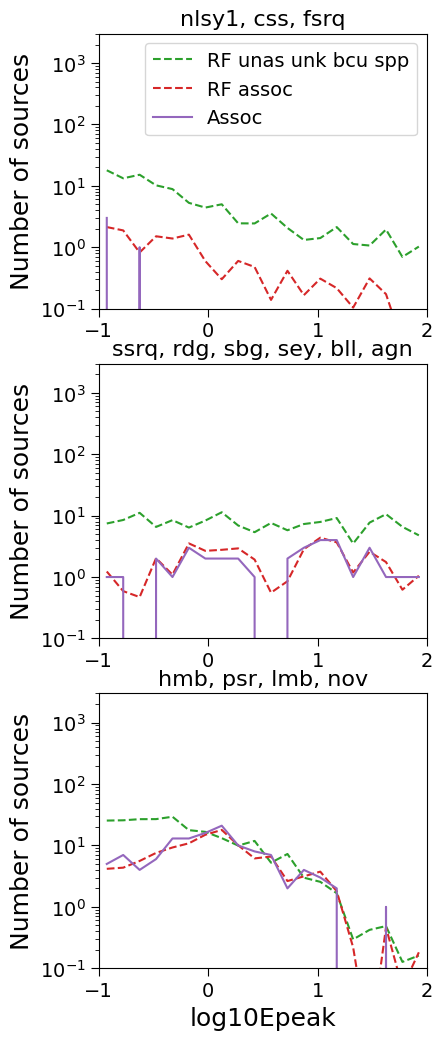

In [38]:
if density:
    ymin = 0.01
    ymax = 10.
else:
    ymin = 0.1
    ymax = 3.e3
plotfn = pyplot.semilogy
pgroup = pgroup1
nrows = len(pgroup)
pyplot.rcParams['figure.figsize'] =  fig_size1


pyplot.figure()
for ind, node in enumerate(pgroup):
    ax = pyplot.subplot(nrows, ncols, ind + 1)
    if plot_all_assoc:
        plotfn(binc, hist_all_assoc, ls=':', c=colors[0], label='Assoc')
        plotfn(binc, hist_all_unassoc, ls=':', c=colors[1], label=unas_label)
    ci = 2
    
    for alg in algs:
        key = '%s_%s' % (node, alg)
        plotfn(binc, unas_hists[key], ls=lss[alg], c=colors[ci], 
                         label='%s %s' % (alg, unas_label))
    ci += 1
    
    for alg in algs:
        key = '%s_%s' % (node, alg)
        plotfn(binc, assoc_prob_hists[key], ls=lss[alg], c=colors[ci], 
                         label=alg + ' assoc')
    ci += 1
    plotfn(binc, assoc_count_hists[node], ls='-', c=colors[ci], 
                     label='Assoc')
    
    #pyplot.xlim(-12.5, -9)
    pyplot.xlim(xmin, xmax)
    pyplot.ylim(ymin, ymax)
    if ind == 0:
        #pyplot.legend(loc='upper right')
        pyplot.legend(loc='best')
    if ind == len(pgroup) - 1:
        pyplot.xlabel(xlabel)
    pyplot.ylabel('Number of sources')
    cls_str = util.cl_list2str(dec_tree_cat_dict[int(node)])
    pyplot.title(cls_str)
    #pyplot.grid()
if save_plots and purpose != 'DFG':
    fn = plots_folder + '%s_distr_group1%s.pdf' % (var_name, descr_str)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn)
    if save_png:
        fn_png = fn.replace('.pdf', '.png')
        pyplot.savefig(fn_png)
    if copy2tex:
        fn_paper = fn.replace(plots_folder, plots_folder_paper)
        cmd = 'cp %s %s' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)



save figure to file: ../..//plots/pop_study/4FGL-DR4_5classes_GMM_no_bcu_spp_no_coord_features/log10Epeak_distr_group24FGL-DR4_5classes_GMM_no_bcu_spp_no_coord_features_all_not_assoc.pdf


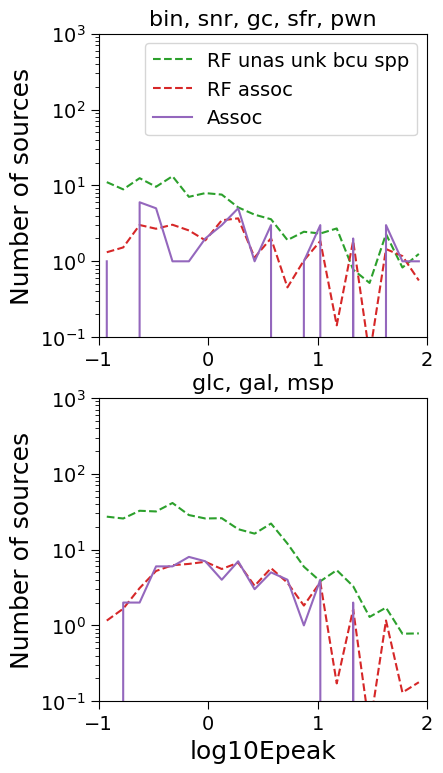

In [39]:
pgroup = pgroup2
if density:
    ymin = 0.01
    ymax = 10.
else:
    ymin = 0.1
    ymax = 1.e3
plotfn = pyplot.semilogy

nrows = len(pgroup)
pyplot.rcParams['figure.figsize'] =  fig_size2


pyplot.figure()
for ind, node in enumerate(pgroup):
    ax = pyplot.subplot(nrows, ncols, ind + 1)
    if node not in assoc_count_hists:
        continue

    if plot_all_assoc:
        plotfn(binc, hist_all_assoc, ls=':', c=colors[0], label='Assoc')
        plotfn(binc, hist_all_unassoc, ls=':', c=colors[1], label=unas_label)
    ci = 2
    
    for alg in algs:
        key = '%s_%s' % (node, alg)
        plotfn(binc, unas_hists[key], ls=lss[alg], c=colors[ci], 
                         label='%s %s' % (alg, unas_label))
    ci += 1
    
    for alg in algs:
        key = '%s_%s' % (node, alg)
        plotfn(binc, assoc_prob_hists[key], ls=lss[alg], c=colors[ci], 
                         label=alg + ' assoc')
    ci += 1
    plotfn(binc, assoc_count_hists[node], ls='-', c=colors[ci], 
                     label='Assoc')
    
    #pyplot.xlim(-12.5, -9)
    pyplot.xlim(xmin, xmax)
    pyplot.ylim(ymin, ymax)
    if ind == 0:
        #pyplot.legend(loc='upper right')
        pyplot.legend(loc='best')
    if ind == len(pgroup) - 1:
        pyplot.xlabel(xlabel)
    pyplot.ylabel('Number of sources')
    cls_str = util.cl_list2str(dec_tree_cat_dict[int(node)])
    pyplot.title(cls_str)
if save_plots and purpose != 'DFG':
    fn = plots_folder + '%s_distr_group2%s.pdf' % (var_name, descr_str)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn)
    if save_png:
        fn_png = fn.replace('.pdf', '.png')
        pyplot.savefig(fn_png)
    if copy2tex:
        fn_paper = fn.replace(plots_folder, plots_folder_paper)
        cmd = 'cp %s %s' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)



In [40]:
# determine evolution of parameters as a function of latitude or another parameter
bin_coord = 'sin(GLAT)'
#bin_coord = 'log10(Energy_Flux100)'
#bin_coord = 'log10(Pivot_Energy)'
if bin_coord == 'sin(GLAT)':
    lat_bins = [0, 10, 30, 90]
    vbins = np.sin(np.deg2rad(lat_bins))
elif bin_coord == 'log10(Energy_Flux100)':
    vbins = np.array([-12.5, -11.5, -10.5, -7.5])
elif bin_coord == 'TS':
    df_extra['TS'] = np.sum(ctab['Sqrt_TS_Band']**2, axis=1)
    xdf['TS'] = df_extra['TS'][xdf.index]
    vbins = np.array([10, 100, 500, 1.e6])
elif bin_coord == 'log10(Pivot_Energy)':
    df_extra['log10(Pivot_Energy)'] = np.log10(ctab['Pivot_Energy']) - 3.
    xdf['log10(Pivot_Energy)'] = df_extra['log10(Pivot_Energy)'][xdf.index]
    vbins = np.arange(-0.5, 1.1, 0.5)
    
def vv2label(vv):
    if bin_coord == 'sin(GLAT)':
        return '%i' % np.round(np.rad2deg(np.arcsin(vv)))
    elif bin_coord == 'log10(Energy_Flux100)':
        return '%.1f' % vv
    elif bin_coord == 'TS':
        return '%g' % vv
    else:
        return vv
    
    
nbins = len(vbins) - 1
mean_dict = {}
std_dict = {}
sample_std_dict = {}

hist_all_assoc = {}
hist_all_unassoc = {}
assoc_count_hists = {}
assoc_prob_hists = {}
unas_hists = {}

for i in range(nbins):
    sinb_min = vbins[i]
    sinb_max = vbins[i + 1]
    if bin_coord == 'sin(GLAT)':
        bin_mask = (np.abs(xdf[bin_coord]) > vbins[i]) & (np.abs(xdf[bin_coord]) < vbins[i + 1])
    else: #elif bin_coord == 'log10(Energy_Flux100)':
        bin_mask = (xdf[bin_coord] > vbins[i]) & (xdf[bin_coord] < vbins[i + 1])
    

    fmask = bin_mask #fmask_llat & fmask_lon_in # fmask_hlat #
    hist_all_assoc[i] = np.histogram(values[assoc_mask & fmask], bins=bins, density=density)[0]
    hist_all_unassoc[i] = np.histogram(values[unas_mask & fmask], bins=bins, density=density)[0]

    mean_dict[i] = {'assoc':{}, 'unas':{}}
    std_dict[i] = {'assoc':{}, 'unas':{}}
    
    sample_std_dict[i] = {'assoc':{}, 'unas':{}}

    assoc_count_hists[i] = {}
    assoc_prob_hists[i] = {}
    unas_hists[i] = {}
    for node in nodes:
        assoc_count_hists[i][node] = np.histogram(values[cls_masks[node] & fmask], bins=bins, density=density)[0]
        if mask_outliers:
            vmask = (values > xmin) & (values < xmax) # outlier mask?
        else:
            vmask = True
        mean_dict[i]['assoc'][node] = np.mean(values[cls_masks[node] & fmask & vmask])
        std_dict[i]['assoc'][node] = np.std(values[cls_masks[node] & fmask & vmask]) / np.sqrt(sum(fmask & vmask))
        sample_std_dict[i]['assoc'][node] = std_dict[i]['assoc'][node] * np.sqrt(sum(fmask & vmask))

        for alg in algs:
            key = '%s_%s' % (node, alg)
            assoc_prob_hists[i][key] = np.histogram(values[assoc_mask & fmask], bins=bins, 
                                          weights=cat_df[key][assoc_mask & fmask], density=density)[0]
            unas_hists[i][key] = np.histogram(values[unas_mask & fmask], bins=bins, 
                                          weights=cat_df[key][unas_mask & fmask], density=density)[0]
            weights = cat_df[key][unas_mask & fmask & vmask]
            mean_dict[i]['unas'][key] = np.sum(values[unas_mask & fmask & vmask] * weights) / np.sum(weights)
            var = np.sum((values[unas_mask & fmask & vmask] - mean_dict[i]['unas'][key])**2 * weights**2) 
            var /= np.sum(weights)**2
            std_dict[i]['unas'][key] = np.sqrt(var)
            sample_std_dict[i]['unas'][key] = std_dict[i]['unas'][key] * np.sqrt(np.sum(weights))


In [41]:
#assoc_count_hists

In [42]:
#mean_dict

In [43]:
#std_dict

In [44]:
# parameters for 5 or 6 panels
nrows = 3
ncols = 2
fig_height = 2.5 * nrows + 2   # height in inches
fig_width = 3 * ncols + 3  # width in inches

#all_plots_pars = {'axes.titlesize':18}
all_plots_pars = {'bottom':0.08, 'top':0.95, 'left':0.12, 'right':0.97, 'axes.titlesize':16}
fig_size =  [fig_width, fig_height]
all_plots_pars['fig_size'] = fig_size
all_plots_pars['font.size'] = 11
all_plots_pars['legend.fontsize'] = 11
putil.setup_figure_pars(pars_dict=all_plots_pars)


0

save figure to file: ../..//plots/pop_study/4FGL-DR4_5classes_GMM_no_bcu_spp_no_coord_features/sin_GLAT_profile_log10Epeak_4FGL-DR4_5classes_GMM_no_bcu_spp_no_coord_features_all_not_assoc.pdf


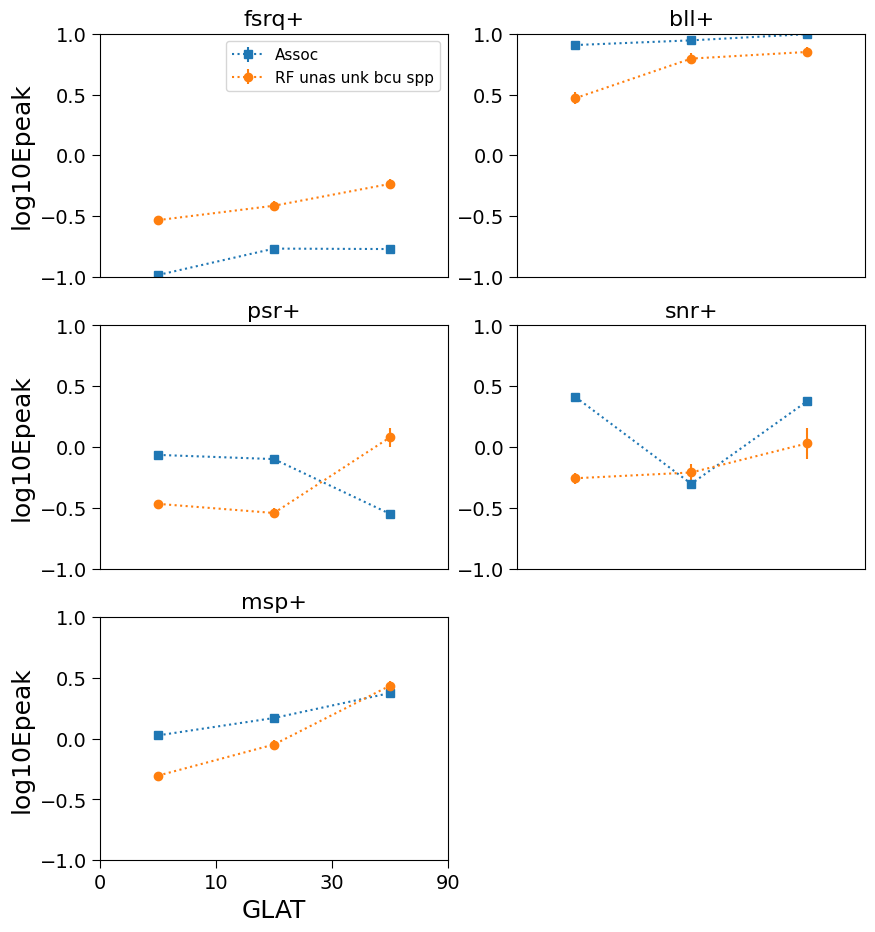

In [45]:
alg = 'RF'
#save_plots = 1
#copy2tex = 1
#putil.setup_figure_pars()
pyplot.figure()
for ind, node in enumerate(nodes):
    ax = pyplot.subplot(nrows, ncols, ind + 1)
    xs = np.arange(nbins) + 0.5
    keys = range(nbins)
    y_assoc = [mean_dict[x]['assoc'][node] for x in keys]
    err_assoc = [std_dict[x]['assoc'][node] for x in keys]
    y_unas = [mean_dict[x]['unas']['%s_%s' % (node, alg)] for x in keys]
    err_unas = [std_dict[x]['unas']['%s_%s' % (node, alg)] for x in keys]
    pyplot.errorbar(xs, y_assoc, err_assoc, ls=':', marker='s', label='Assoc')
    pyplot.errorbar(xs, y_unas, err_unas, ls=':', marker='o', label='%s %s' % (alg, unas_label))
    #cls_str = util.cl_list2str(dec_tree_cat_dict[int(node)])
    title = util.get_max_class(dec_tree_cat_dict[int(node)], nsrc_df) 
    if len(dec_tree_cat_dict[int(node)]) > 1:
        title += '+'
    pyplot.title(title)
    
    if ind == 0:
        pyplot.legend(loc='best')
    if ind % ncols == 0:
        pyplot.ylabel(xlabel)
    if ind < ncols * (nrows - 1):
        ax.axes.xaxis.set_visible(False)
    else:
        if bin_coord == 'sin(GLAT)':
            pyplot.xlabel('GLAT')
        else:
            pyplot.xlabel(bin_coord)
        
    if bin_coord == 'sin(GLAT)':
        pyplot.xticks(ticks=np.arange(len(vbins)), labels=lat_bins)
    elif bin_coord == 'log10(Energy_Flux100)':
        pyplot.xticks(ticks=np.arange(len(vbins)), labels=vbins)
    elif bin_coord == 'TS':
        pyplot.xticks(ticks=np.arange(len(vbins)), labels=vbins)
    else:
        pyplot.xticks(ticks=np.arange(len(vbins)), labels=vbins)

    
    if xlabel == 'Pivot_Energy':
        pyplot.ylim(0.3, 10)
        pyplot.yscale('log')
    if xlabel == 'log10Epeak':
        pyplot.ylim(-1., 1)

if save_plots:
    fn = plots_folder + '%s_profile_%s_%s.pdf' % (bin_coord, var_name, descr_str)
    fn = fn.replace('(', '_')
    fn = fn.replace(')', '_')
    fn = fn.replace('__', '_')
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn)
    if save_png:
        fn_png = fn.replace('.pdf', '.png')
        print(fn_png)
        #pyplot.savefig(fn_png)
    if copy2tex:
        fn_paper = fn.replace(plots_folder, plots_folder_paper)
        cmd = 'cp %s %s' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)

#save_plots = 0
#copy2tex = 0


In [46]:
def log_par_sp(Es, E0, indE0, beta):
    logE = np.log(Es/E0)
    return np.exp(-np.outer(indE0, logE)  - np.outer(beta, logE**2))

In [47]:
putil.setup_figure_pars(pars_dict=fig_1d_dict)

0

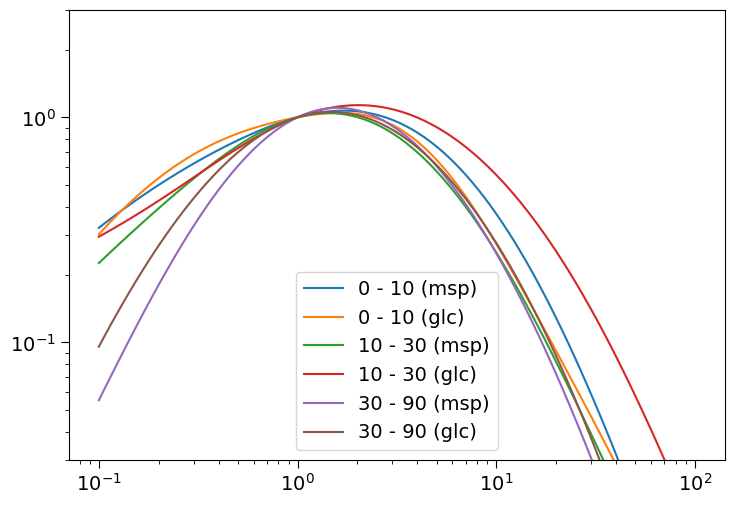

In [48]:
cl = 'glc'
E0 = 1.
Es = np.logspace(-1, 2, 100)
pyplot.figure()
for i in range(len(vbins) - 1):

    for cl in ['msp', 'glc']:
        vmask = vbins[i] < xdf[bin_coord]
        vmask &= vbins[i + 1] > xdf[bin_coord]    
        vmask &= xdf['CLASS1'] == cl
        nms = sum(vmask)
        indE0 = xdf['LP_index1000MeV'][vmask]
        beta = xdf['LP_beta'][vmask]
        ys = log_par_sp(Es, E0, indE0, beta) * Es**2
        if bin_coord == 'sin(GLAT)':
            label = '%i - %i (%s)' % (lat_bins[i], lat_bins[i + 1], cl)
        else:
            label = '%s = %.1g - %.1g' % (bin_coord, vbins[i], vbins[i + 1])

        if 0:
            ymean = np.median(ys, axis=0)
            ymin = np.percentile(ys, 10, axis=0)
            ymax = np.percentile(ys, 90, axis=0)
        elif 0:
            ymean = np.mean(ys, axis=0)
            ystd = np.std(ys, axis=0)
            ymin = ymean - ystd
            ymax = ymean + ystd
        elif 1:
            ymean = np.mean(ys, axis=0)
            ymin = np.min(ys, axis=0)
            ymax = np.max(ys, axis=0)
        pyplot.loglog(Es, ymean, label=label)
        #pyplot.fill_between(Es, ymin, ymax, alpha=0.3)
    pyplot.xscale('log')
    pyplot.yscale('log')
    pyplot.ylim(0.03, 3)
    pyplot.legend()

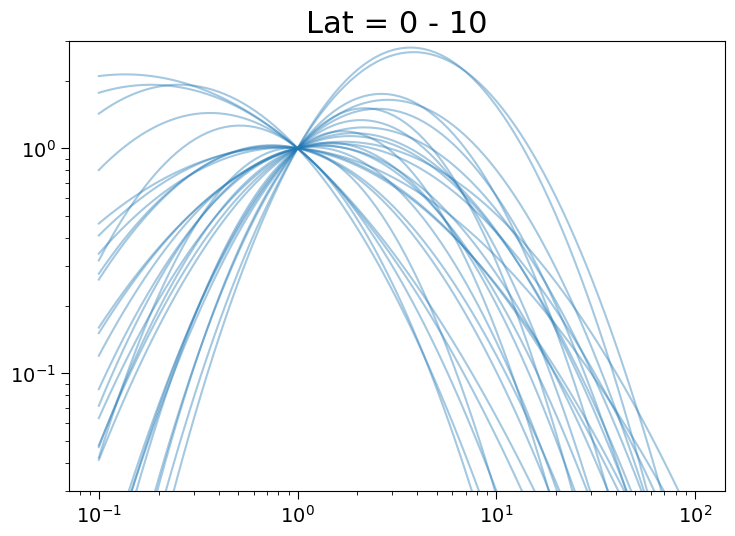

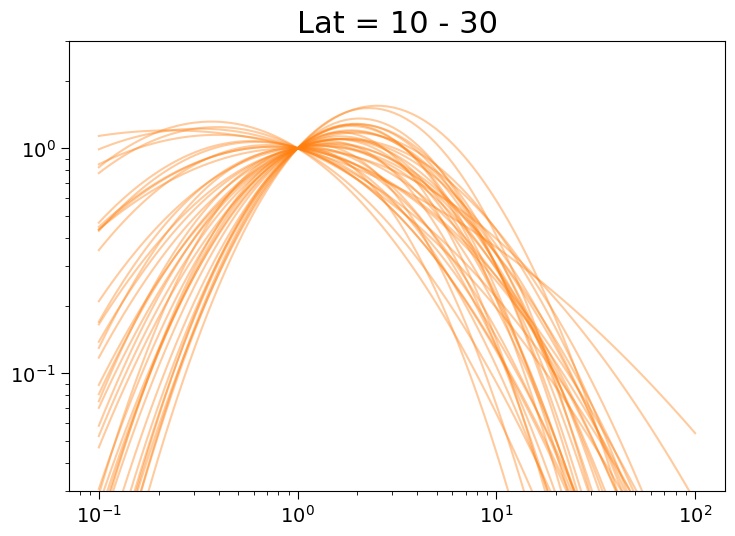

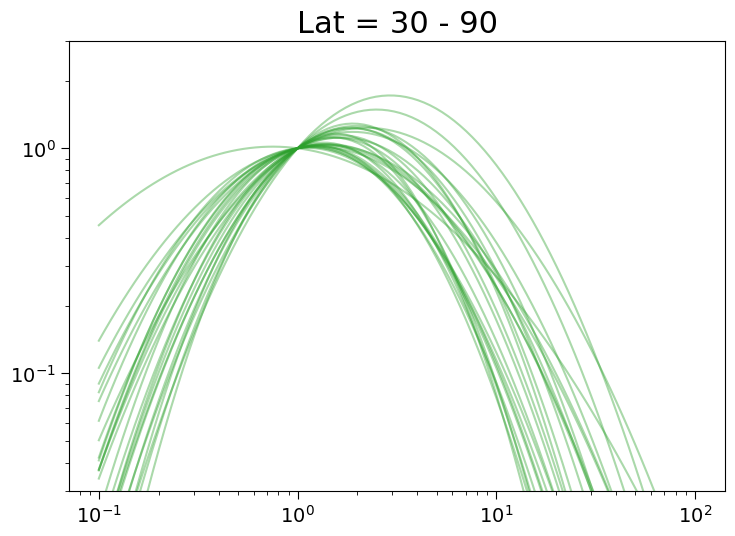

In [49]:
cl = 'msp'
E0 = 1.
Es = np.logspace(-1, 2, 100)
for i in range(len(vbins) - 1):
    pyplot.figure()
    vmask = vbins[i] < xdf[bin_coord]
    vmask &= vbins[i + 1] > xdf[bin_coord]
    vmask &= xdf['CLASS1'] == cl
    indE0 = xdf['LP_index1000MeV'][vmask]
    beta = xdf['LP_beta'][vmask]
    ys = log_par_sp(Es, E0, indE0, beta) * Es**2
    if bin_coord == 'sin(GLAT)':
        label = 'Lat = %i - %i' % (lat_bins[i], lat_bins[i + 1])
    else:
        label = '%s = %.1g - %.1g' % (bin_coord, vbins[i], vbins[i + 1])
    for yy in ys:
        pyplot.loglog(Es, yy, color=colors[i], alpha=0.4)
    pyplot.xscale('log')
    pyplot.yscale('log')
    pyplot.ylim(0.03, 3)
    pyplot.title(label)

Text(0.5, 0, 'log10Epeak')

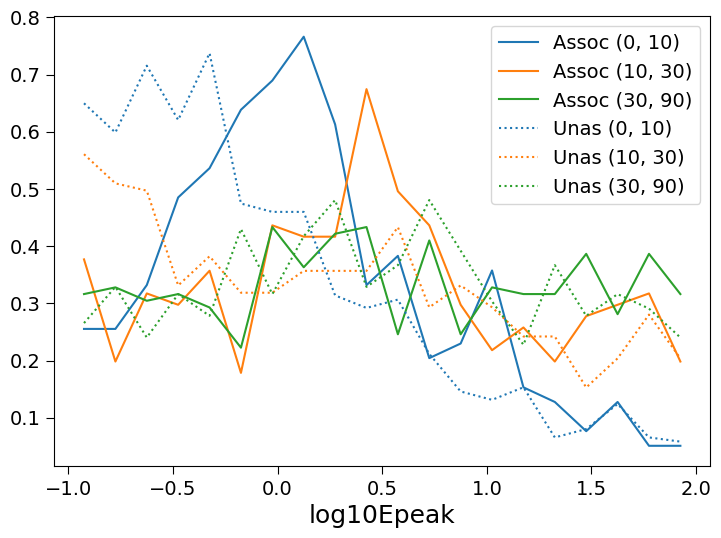

In [50]:
#plot histograms for different latitude bins
alg = 'RF'

putil.setup_figure_pars(pars_dict=fig_1d_dict)

pyplot.figure()
#ax = pyplot.subplot(1, 2, 1)
plot_density = True

for ib in range(nbins):
    ys = hist_all_assoc[ib]
    if plot_density:
        ys = 1. * ys / (sum(ys) * dx)
    label = 'Assoc (%s, %s)' % (vv2label(vbins[ib]), vv2label(vbins[ib + 1]))
    pyplot.plot(binc, ys, color=colors[ib], label=label)

#ax = pyplot.subplot(1, 2, 2)

for ib in range(nbins):
    ys = hist_all_unassoc[ib]
    if plot_density:
        ys = 1. * ys / (sum(ys) * dx)
    label = 'Unas (%s, %s)' % (vv2label(vbins[ib]), vv2label(vbins[ib + 1]))
    pyplot.plot(binc, ys, ls=':', color=colors[ib], label=label)

#pyplot.title('All unassoc')
pyplot.legend()
pyplot.xlabel(xlabel)



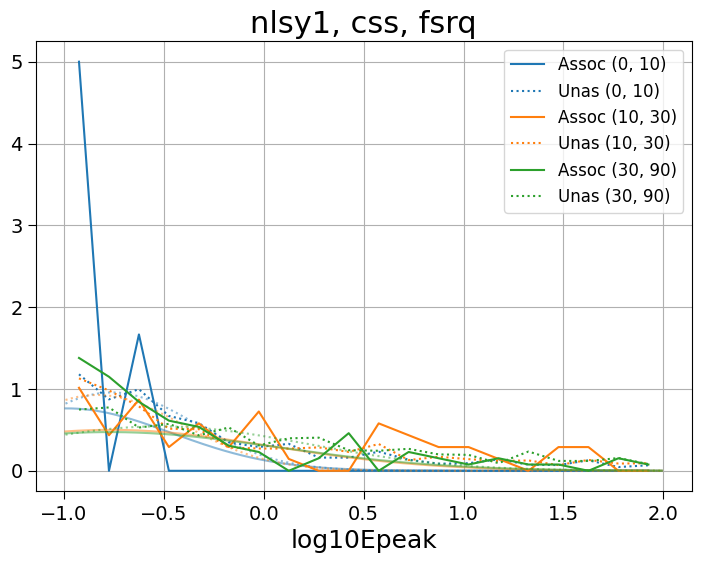

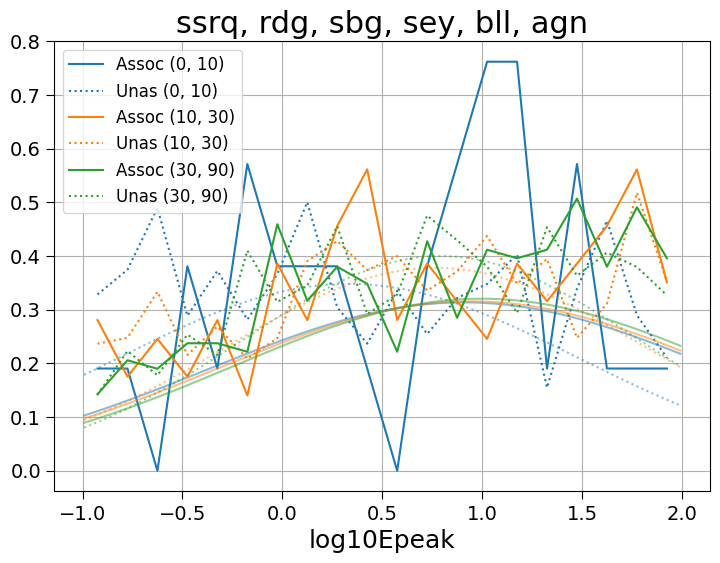

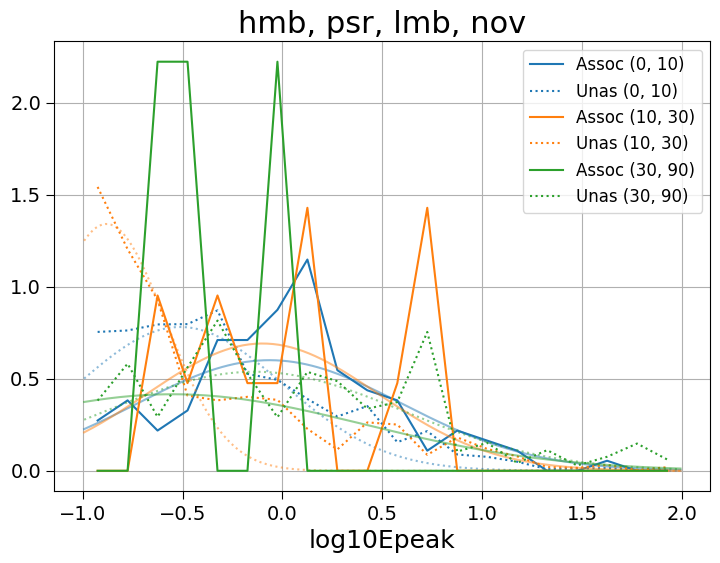

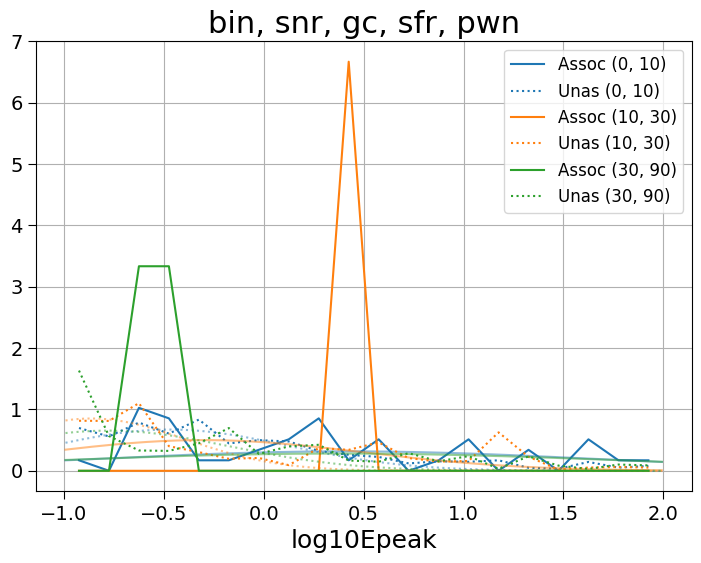

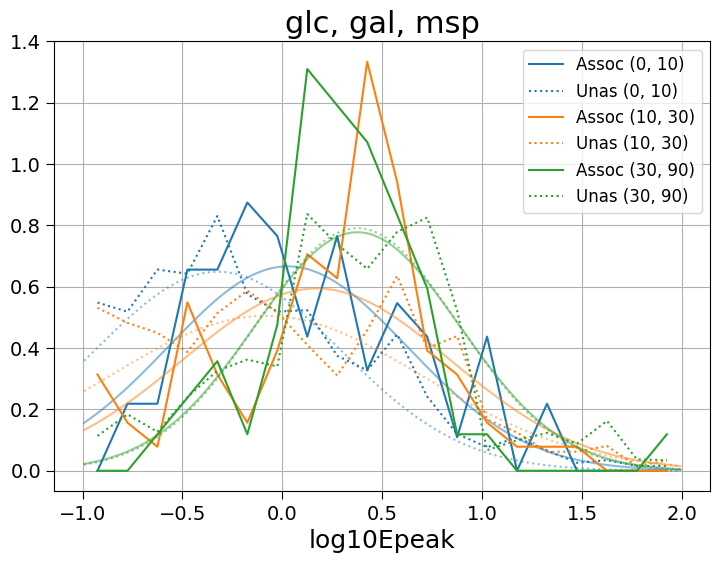

In [51]:
plot_density = 1
for node in nodes:
    pyplot.figure()
    for ib in range(nbins):
        ys = assoc_count_hists[ib][node]
        if plot_density:
            ys = 1. * ys / (sum(ys) * dx)
        label = 'Assoc (%s, %s)' % (vv2label(vbins[ib]), vv2label(vbins[ib + 1]))
        pyplot.plot(binc, ys, color=colors[ib], label=label)
        
        if plot_density:
            mu = mean_dict[ib]['assoc'][node]
            std = sample_std_dict[ib]['assoc'][node]
            pyplot.plot(binc_gauss, gauss_pdf(mu, std)(binc_gauss), alpha=0.5, c=colors[ib])
            
        ys = unas_hists[ib]['%s_%s' %(node, alg)]
        if plot_density:
            ys = 1. * ys / (sum(ys) * dx)
        label = 'Unas (%s, %s)' % (vv2label(vbins[ib]), vv2label(vbins[ib + 1]))
        pyplot.plot(binc, ys, color=colors[ib], ls=':', label=label)
        
        if plot_density:
            def objf(pars):
                return np.sum((gauss_pdf(pars[0], pars[1])(binc) - ys)**2)
            mu = mean_dict[ib]['unas'][key]
            std = sample_std_dict[ib]['unas'][key]
            pars0 = [mu, std]
            mu, std = minimize(objf, pars0).x
            #print(res)
            pyplot.plot(binc_gauss, gauss_pdf(mu, std)(binc_gauss), ls=':', alpha=0.5, c=colors[ib])

    
    cls_str = util.cl_list2str(dec_tree_cat_dict[int(node)])
    pyplot.title(cls_str)
    pyplot.legend(fontsize=12)
    pyplot.grid()
    #pyplot.xlim(1, 3.5)
    pyplot.xlabel(xlabel)

In [52]:
#nsrc_dict = util.get_nsrc_dict(xdf, class_column='CLASS1', classes='associated')

save figure to file: ../..//plots/pop_study/4FGL-DR4_5classes_GMM_no_bcu_spp_no_coord_features/extra/assoc_sources_distribution_lat0-10_all_not_assoc_log10Epeak.pdf


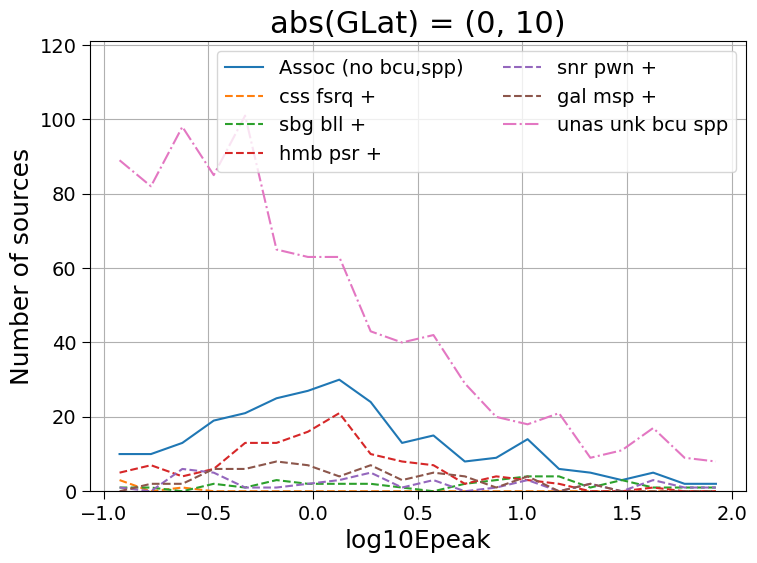

In [53]:
# plot associated sources classes in a bin
putil.setup_figure_pars(pars_dict=fig_1d_dict)

plot_density = 0
add_unas = 1
divide_unas = 0
if divide_unas:
    factor = 4
ib = 0
pyplot.figure()
ys = hist_all_assoc[ib]
if plot_density:
    ys = 1. * ys / sum(ys)
label = 'Assoc'
if assoc_sources == 'no_bcu_spp':
    label += ' (no bcu,spp)'

pyplot.plot(binc, ys, label=label)

for node in nodes:
    ys = assoc_count_hists[ib][node]
    if plot_density:
        ys = 1. * ys / sum(ys)
    #cls_str = util.cl_list2str(dec_tree_cat_dict[int(node)])
    label = util.list2label(dec_tree_cat_dict[int(node)], nsrc_dict=nsrc_dict, ncl=2, max_only=True)
    pyplot.plot(binc, ys, ls='--', label=label)
    
fr_str = ''
if add_unas:
    ys = hist_all_unassoc[ib]
    if plot_density:
        ys = 1. * ys / sum(ys)
    if ib == 0 and bin_coord == 'sin(GLAT)' and divide_unas:
        label = '%s / %s' % (unas_label, factor)
        fr_str = '_divide_unas_by%i' % factor
    else:
        factor = 1
        label = unas_label
    
    pyplot.plot(binc, ys / factor, ls='-.', label=label)
    
if not plot_density:
    pyplot.ylim(0, np.max(hist_all_unassoc[ib]) + 20)
pyplot.legend(ncol=2)
pyplot.xlabel(var_name)
if var_name == 'Pivot_Energy':
    pyplot.xscale('log')
if plot_density:
    pyplot.ylabel('Source density')
else:
    pyplot.ylabel('Number of sources')
if bin_coord == 'sin(GLAT)':
    pyplot.title('%s = (%s, %s)' % ('abs(GLat)', vv2label(vbins[ib]), vv2label(vbins[ib + 1])))
else:
    pyplot.title('%s = (%s, %s)' % (bin_coord, vv2label(vbins[ib]), vv2label(vbins[ib + 1])))
    
pyplot.grid()

#save_plots = 1
if save_plots:
    if bin_coord == 'sin(GLAT)':
        fn = plots_folder_extra + 'assoc_sources_distribution_lat%s-%s%s_%s_%s.pdf' % \
               (vv2label(vbins[ib]), vv2label(vbins[ib + 1]), fr_str, unas_type, var_name)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn)
    if save_png:
        fn_png = fn.replace('.pdf', '.png')
        pyplot.savefig(fn_png)


save figure to file: ../..//plots/pop_study/4FGL-DR4_5classes_GMM_no_bcu_spp_no_coord_features/extra/unas_sources_distribution_lat0-10_all_not_assoc_log10Epeak.pdf


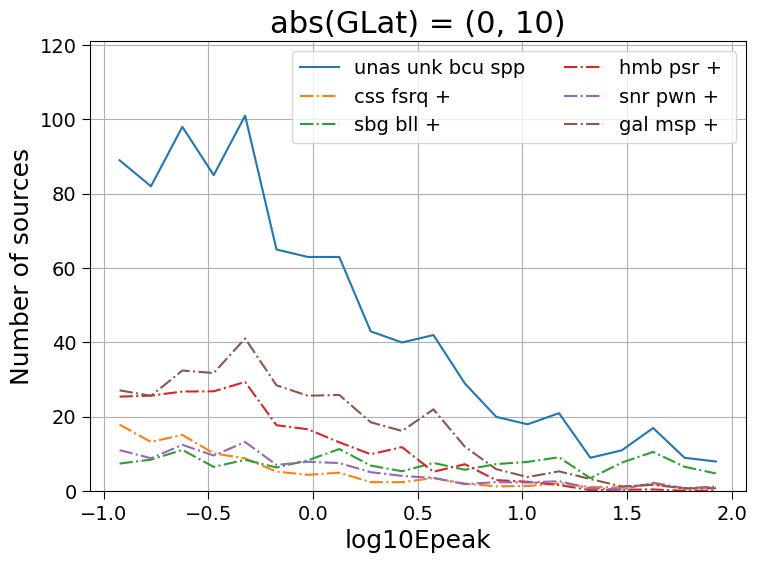

In [54]:
# plot unassociated sources classes in a bin
plot_density = 0
add_assoc = 0
ib = 0
bins_loc = [ib]
pyplot.figure()
ys = hist_all_unassoc[ib]
if plot_density:
    ys = 1. * ys / sum(ys)
label = unas_label
pyplot.plot(binc, ys, label=label)

for node in nodes:
    for ib in bins_loc:
        ys = unas_hists[ib]['%s_%s' %(node, alg)]
        if plot_density:
            ys = 1. * ys / sum(ys)
        #cls_str = util.cl_list2str(dec_tree_cat_dict[int(node)])
        label = util.list2label(dec_tree_cat_dict[int(node)], nsrc_dict=nsrc_dict, ncl=2, max_only=True)
        pyplot.plot(binc, ys, ls='-.', c=colors[int(node)], label=label)

assoc_str = ''
if ib == 0 and add_assoc:
    assoc_str = '_add_assoc'
    for node in nodes[:]:
        for ib in bins_loc:
            ys = assoc_count_hists[ib][node]
            if plot_density:
                ys = 1. * ys / sum(ys)
            #cls_str = util.cl_list2str(dec_tree_cat_dict[int(node)])
            cls_str = util.list2label(dec_tree_cat_dict[int(node)], nsrc_dict=nsrc_dict, ncl=2, max_only=True)
            if 0:
                pfactor = 3
                label = 'Assoc %s' % (cls_str)
                pyplot.plot(binc, pfactor * ys, ls='--', c=colors[int(node)], label=label)
            if plot_density or unas_type not in ['unas', 'all_not_assoc']:
                pfactor = 1
                label = 'Assoc %s' % (cls_str)
            elif not plot_density and unas_type == 'all_not_assoc':
                pfactor = 3
                label = 'Assoc %s (x%i)' % (cls_str, pfactor)                
            else:
                pfactor = 2
                label = 'Assoc %s (x%i)' % (cls_str, pfactor)
            pyplot.plot(binc, pfactor * ys, ls='--', c=colors[int(node)], label=label)

if not plot_density:
    pyplot.ylim(0, np.max(hist_all_unassoc[ib]) + 20)
pyplot.legend(ncol=2)
pyplot.xlabel(var_name)
if var_name == 'Pivot_Energy':
    pyplot.xscale('log')

if plot_density:
    pyplot.ylabel('Source density')
else:
    pyplot.ylabel('Number of sources')
if bin_coord == 'sin(GLAT)':
    pyplot.title('%s = (%s, %s)' % ('abs(GLat)', vv2label(vbins[ib]), vv2label(vbins[ib + 1])))
else:
    pyplot.title('%s = (%s, %s)' % (bin_coord, vv2label(vbins[ib]), vv2label(vbins[ib + 1])))
    
pyplot.grid()

#save_plots = 1
if save_plots:
    if bin_coord == 'sin(GLAT)':
        fn = plots_folder_extra + 'unas_sources_distribution_lat%s-%s_%s_%s%s.pdf' % \
               (vv2label(vbins[ib]), vv2label(vbins[ib + 1]), unas_type, var_name, assoc_str)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn)
    if save_png:
        fn_png = fn.replace('.pdf', '.png')
        pyplot.savefig(fn_png)

